In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
#from graph_walks import GraphWalker
#from analytical_distribution import AnalyticalDistribution
#from distribution_distance import DistributionDistance

from frt_distributions import GraphWalker, AnalyticalDistribution, DistributionDistance, calc_distance, generate_embedding, mean_variance_embedding
from visualisations import AnimateWalk, highlight_node_and_neighbors
from scipy import optimize
from tqdm import tqdm

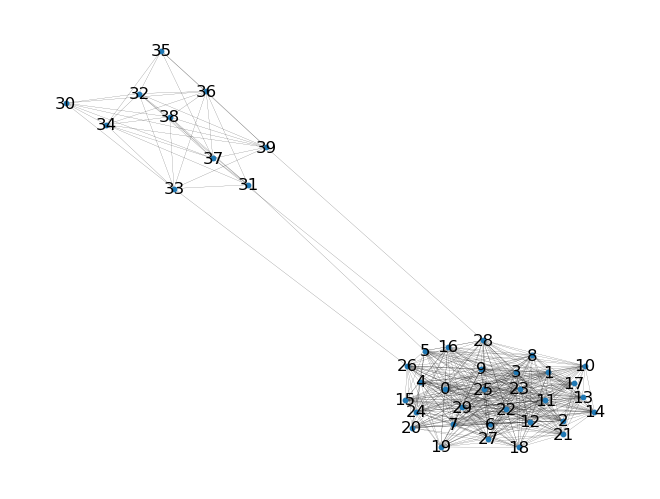

In [1477]:
#G = nx.bull_graph()  # Create a large random graph
#G = nx.lollipop_graph(5, 4)
#G = nx.frucht_graph()
#G = nx.tutte_graph()
#G = nx.graph_atlas(150)
#G = nx.star_graph(5)
#k = 10
sizes = [30, 10]
p = 0.9; q = 0.01
#probs = [[1, 1, 0], [1, 1, 1], [0, 1, 1]]
#probs = [[p, q, 0], [q, p, q], [0, q, p]]
probs = [[p, q], [q, p]]
G = nx.stochastic_block_model(sizes, probs, seed=0)


#G = nx.karate_club_graph()
for u, v in G.edges():
    G[u][v].clear()


#G= nx.erdos_renyi_graph(100, 0.2)
#G = nx.barabasi_albert_graph(100, 3)
#G = nx.davis_southern_women_graph()
#G = nx.florentine_families_graph()
#G = nx.les_miserables_graph()
#G = nx.random_internet_as_graph(1000)
#G = nx.Graph()
#G.add_edges_from([(0, 1), (1, 2), (2, 0), (0, 3), (3, 4), (4, 5), (5, 3)])


#G = nx.read_gml('Little_rock_lake.gml', label='id').to_undirected()
G.remove_edges_from(nx.selfloop_edges(G))
N = len(G.nodes)
#nx.draw(G, pos = nx.bfs_layout(G, 1 , align='horizontal'), with_labels=True)
positions = {}
for node, data in G.nodes(data=True):
    if 'pos' in data:
        pos = data['pos'].split(',')  # Split "x,y" into separate coordinates
        positions[node] = (float(pos[0]), float(pos[1]))


nx.draw(G, with_labels=True, node_size=10, width=0.1)
#nx.draw(G, pos = positions, with_labels=False, node_size=15, node_color='r', alpha=0.5)

In [1479]:
#L1_mat, FRTs = calc_distance(G, max_steps=200, measure='L1', return_dist=True)

emb = generate_embedding(G, M=200, parallel=False)

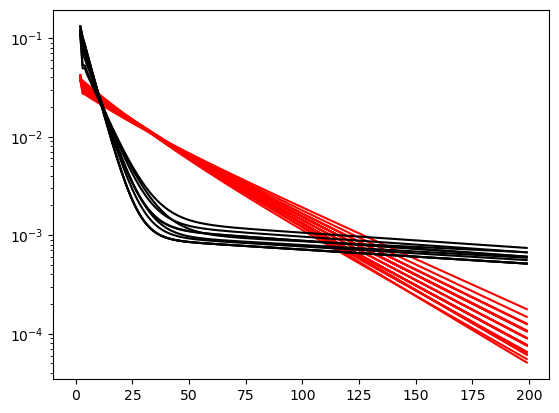

In [1481]:
for i in range(N):
    #plt.plot(FRTs[i].keys(), FRTs[i].values(), label=i)
    if i<30:
        plt.plot(emb[i], color='r')
    else:
        plt.plot(emb[i], color='k')
   #plt.plot(pmf[i].keys(), pmf[i].values())

#x = np.array(list(FRTs[i].keys()))
#y = np.exp(-0*(x+1))
#plt.plot(x, y)

plt.yscale('log', nonpositive='mask')

In [1364]:
A = np.identity(N)-nx.normalized_laplacian_matrix(G).todense()
values, vectors = np.linalg.eigh(A)

In [1366]:
S = np.zeros(N) ; Sdash = np.zeros(N)
for i in range(N-1):
    S += vectors[:, i]**2 * 1/(1-values[i])
    Sdash += values[i]*vectors[:, i]**2 * 1/(1-values[i])**2

In [1427]:
mean = 1/vectors[:, -1]**2
variance = 2*mean**2 * S + mean - mean**2

coeff_approx = 1/mean*S**2

In [1370]:
def Rv(z, node=0):
    result=0
    for j in range(N):
        result += vectors[node, j]**2/(1-values[j]*z)
    return result

def Rvdash(z, node=0):
    result=0
    for j in range(N):
        result += values[j]*vectors[node, j]**2/(1-values[j]*z)**2
    return result

def Fv(z, node=0):
    return 1 - 1/Rv(z, node)

def empirical_rate(embedding, diff=150, node=0):
    return -(np.log(embedding[node, -1]) - np.log(embedding[node, -diff]))/diff

def estimated_rate(node, numerically=False):
    if numerically==True:
        root = optimize.root_scalar(Rv, x0 = 1, args=(node)).root
        return root, np.log(root)

    return 1/(mean[node]*S[node])

In [1372]:
def compute_return_times(A, K = 40):
    emb = np.zeros((len(A), K))
    values, vectors = np.linalg.eigh(A)
    for k in range(K):
        for i in range(len(A)):
            emb[i, k] = np.sum(values**(k+1) * vectors[i, :]**2)
    return emb

returns = compute_return_times(A, K=200)

In [1374]:
emp = np.zeros(N) ; est_numerical = np.zeros(N) ; est = np.zeros(N) ; log_est = np.zeros(N) ; coeff_est = np.zeros(N) ; root = np.zeros(N) ; coeff_num = np.zeros(N)
for node in tqdm(range(N)):
    emp[node] = empirical_rate(emb, node=node)
    root[node], est_numerical[node] = estimated_rate(node, numerically=True)
    est[node] = estimated_rate(node, numerically=False)
    log_est[node] = np.log(1 + est[node])
    coeff_est[node] = 1/Rvdash(1+est[node], node=node)
    coeff_num[node] = 1/Rvdash(root[node], node=node)

100%|███████████████████████████████████████████| 80/80 [00:00<00:00, 95.50it/s]


In [1376]:
pi = [degree/(2*len(G.edges)) for node, degree in G.degree]

Text(0, 0.5, 'Slope')

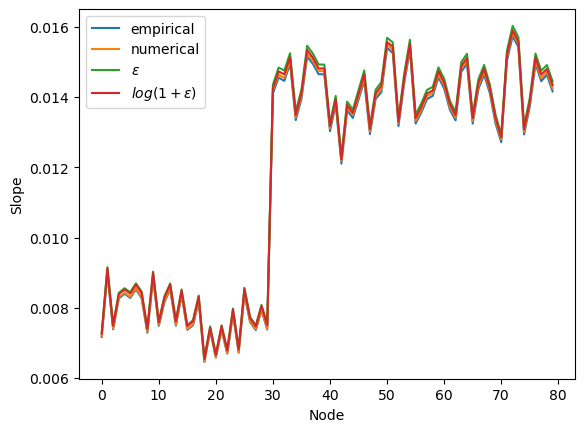

In [1378]:
plt.plot(emp, label='empirical')
plt.plot(est_numerical, label='numerical')
plt.plot(est, label=r'$\epsilon$')
plt.plot(log_est, label=r'$log(1+\epsilon)$')
plt.legend()
plt.xlabel('Node') ; plt.ylabel('Slope')

Text(0, 0.5, '$d_v/2m$')

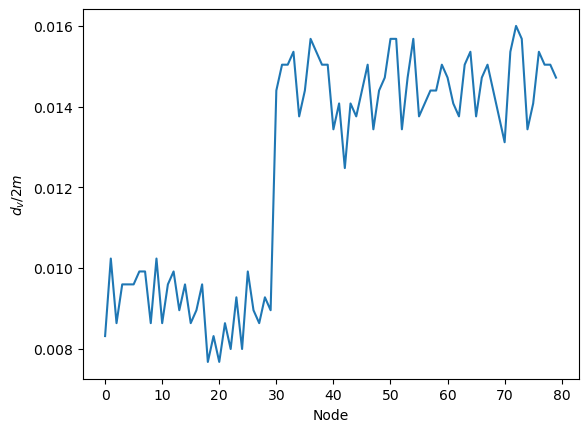

In [1380]:
plt.plot([degree/(2*len(G.edges)) for node, degree in G.degree])
plt.xlabel('Node') ; plt.ylabel(r'$d_v/2m$') 

Text(0, 0.5, 'Absolute Error')

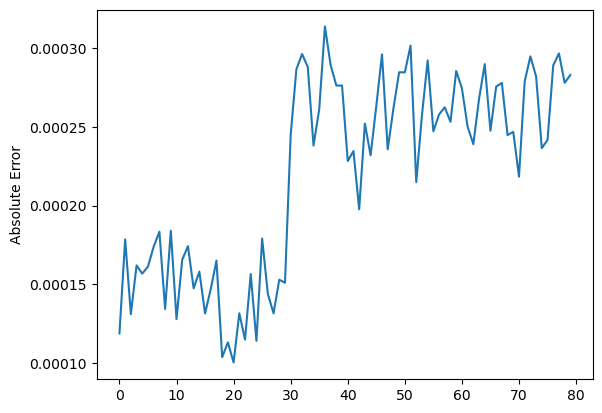

In [1382]:
plt.plot(np.abs(est-emp))
plt.ylabel('Absolute Error')

Text(0, 0.5, 'd/2m')

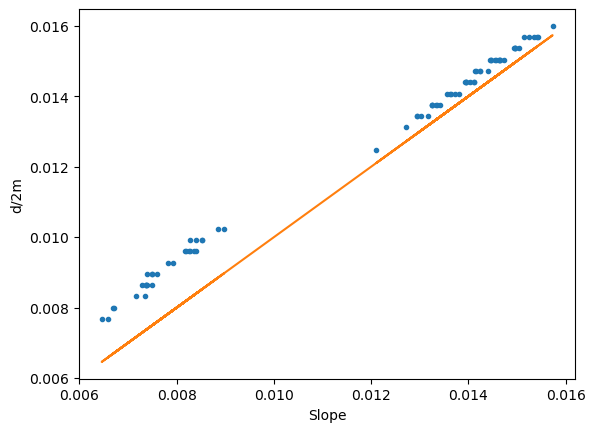

In [1384]:
plt.plot(emp, [degree/(2*len(G.edges)) for node, degree in G.degree], '.')
plt.plot(emp, emp)
plt.xlabel('Slope') ; plt.ylabel('d/2m')

(-10.0, 10.0)

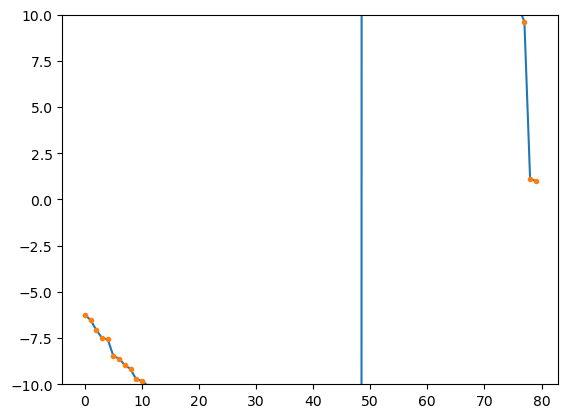

In [1386]:
plt.plot(1/values)
plt.plot(1/values, '.')

plt.ylim(-10, 10)

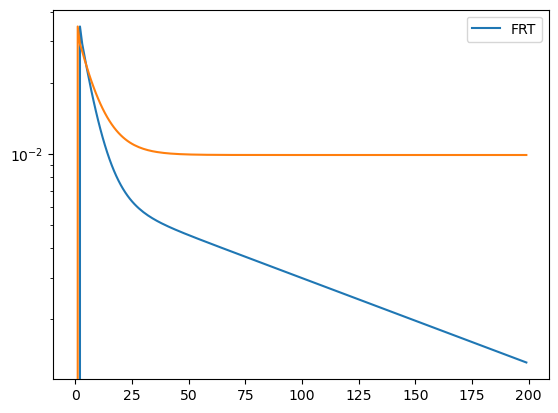

In [1395]:
node = 7
eta = 1
x = np.array(np.arange(len(emb[0, :])))
#T = onset_time(values, vectors, node, eta=eta, degrees = [degree for node, degree in G.degree], m = len(G.edges))[0]
#T = analytic_tail_bound(values, vectors, node=node, eta=eta, use_first_order=True, k_check=[6,16,20], verbose=False)['T_zero']
plt.plot(x, emb[node], label='FRT')
y1 = coeff_est[node] * np.exp(-est[node]*(x+1))
y2 = coeff_num[node] * np.exp(-est_numerical[node]*(x+1))

#plt.vlines(T, np.amin(y1), np.amax(emb[node]), color='k')
plt.plot(x, returns[node])
#plt.hlines(pi[node], 0, 200, linestyle='--', color='k')
#plt.plot(x, y1, label='Analytical Approximation')
#plt.plot(x, y2, label='Numerical root finding approximation')
plt.yscale('log')
plt.legend()

#print(np.amax(np.abs(emb[node, T:] - y2[T:])/y2[T:]))

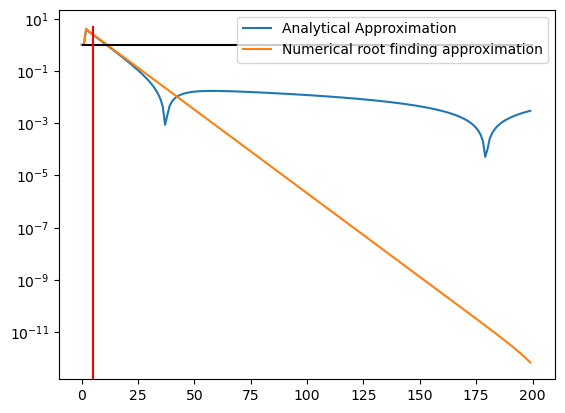

In [1397]:
plt.plot(np.abs(emb[node] - y1)/y1, label='Analytical Approximation')
plt.plot(np.abs(emb[node] - y2)/y2, label='Numerical root finding approximation')
plt.hlines(eta, 0, 200, color='k')
plt.vlines(T+1, 0, 5, color='r')
plt.legend()
plt.yscale('log')

In [1399]:
T

4

Text(0, 0.5, 'S')

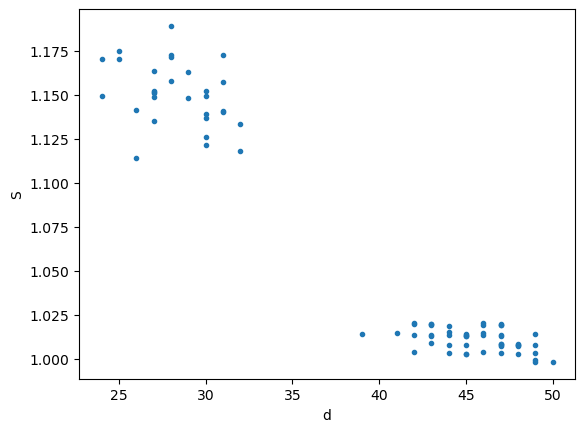

In [1401]:
plt.plot([degree for node, degree in G.degree], S, '.')
plt.xlabel('d') ; plt.ylabel('S')

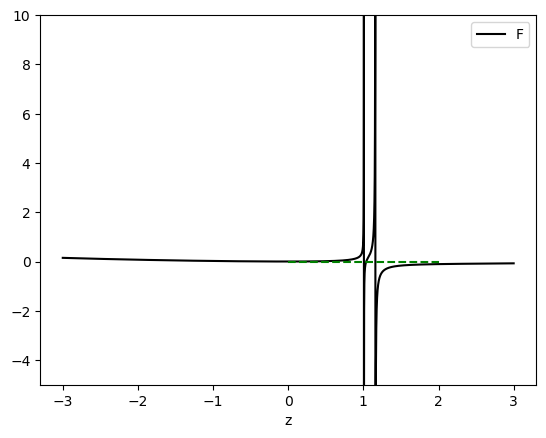

In [1403]:
node = 0
zs = np.linspace(-3, 3, 100000)
#plt.plot(zs, Rv(zs, node=node), label='R')
#plt.plot(zs, Rvdash(zs, node=node))
plt.plot(zs, Fv(zs, node=node), color='k', label='F')
plt.hlines(0, 0, 2, linestyle='--', color='g')
#plt.vlines(1/values[-4:], 0, 10, color='r', linestyle='--')
#plt.vlines(1/values[:4], 0, 10, color='r', linestyle='--')
plt.ylim(-5, 10)
plt.xlabel('z') ; #plt.ylabel(r'$R_v(z)$')
plt.legend()

In [1405]:
root

array([1.00721757, 1.00905483, 1.00743819, 1.00832894, 1.00846834,
       1.00834704, 1.00859264, 1.00834099, 1.00733927, 1.00892165,
       1.00753669, 1.00822978, 1.00858951, 1.00754477, 1.00843349,
       1.00742451, 1.00755445, 1.00824809, 1.00649559, 1.00740445,
       1.00661846, 1.00741963, 1.00673503, 1.00788176, 1.00676276,
       1.00845963, 1.00764727, 1.00741702, 1.0079882 , 1.00743502,
       1.01429758, 1.01474585, 1.01464876, 1.01516307, 1.01351319,
       1.01413435, 1.01535174, 1.01514982, 1.01484608, 1.01484483,
       1.0131907 , 1.01397623, 1.01225007, 1.01379088, 1.01357661,
       1.01411086, 1.01465057, 1.01310215, 1.01412917, 1.01432477,
       1.01561902, 1.01546188, 1.01334009, 1.01459864, 1.01555096,
       1.01341147, 1.01373343, 1.01412224, 1.01421752, 1.01475368,
       1.01442998, 1.01381653, 1.01350395, 1.01492469, 1.01514419,
       1.01340737, 1.01441854, 1.0148316 , 1.0142987 , 1.01341645,
       1.01286986, 1.01524302, 1.01595303, 1.0156399 , 1.01309

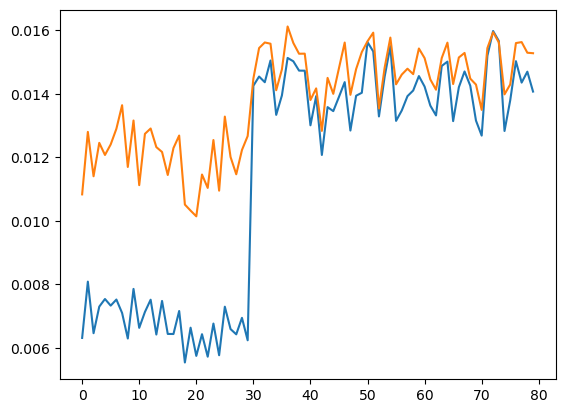

In [1437]:
plt.plot(coeff_est)
plt.plot(coeff_approx)

In [1409]:
1-values[-2]

0.11629211571850495

In [1485]:
np.sum(vectors**2, axis=0)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])